In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error as mae
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, ElasticNetCV

In [65]:
df = pd.read_csv('housing.csv')
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


# Задание 1

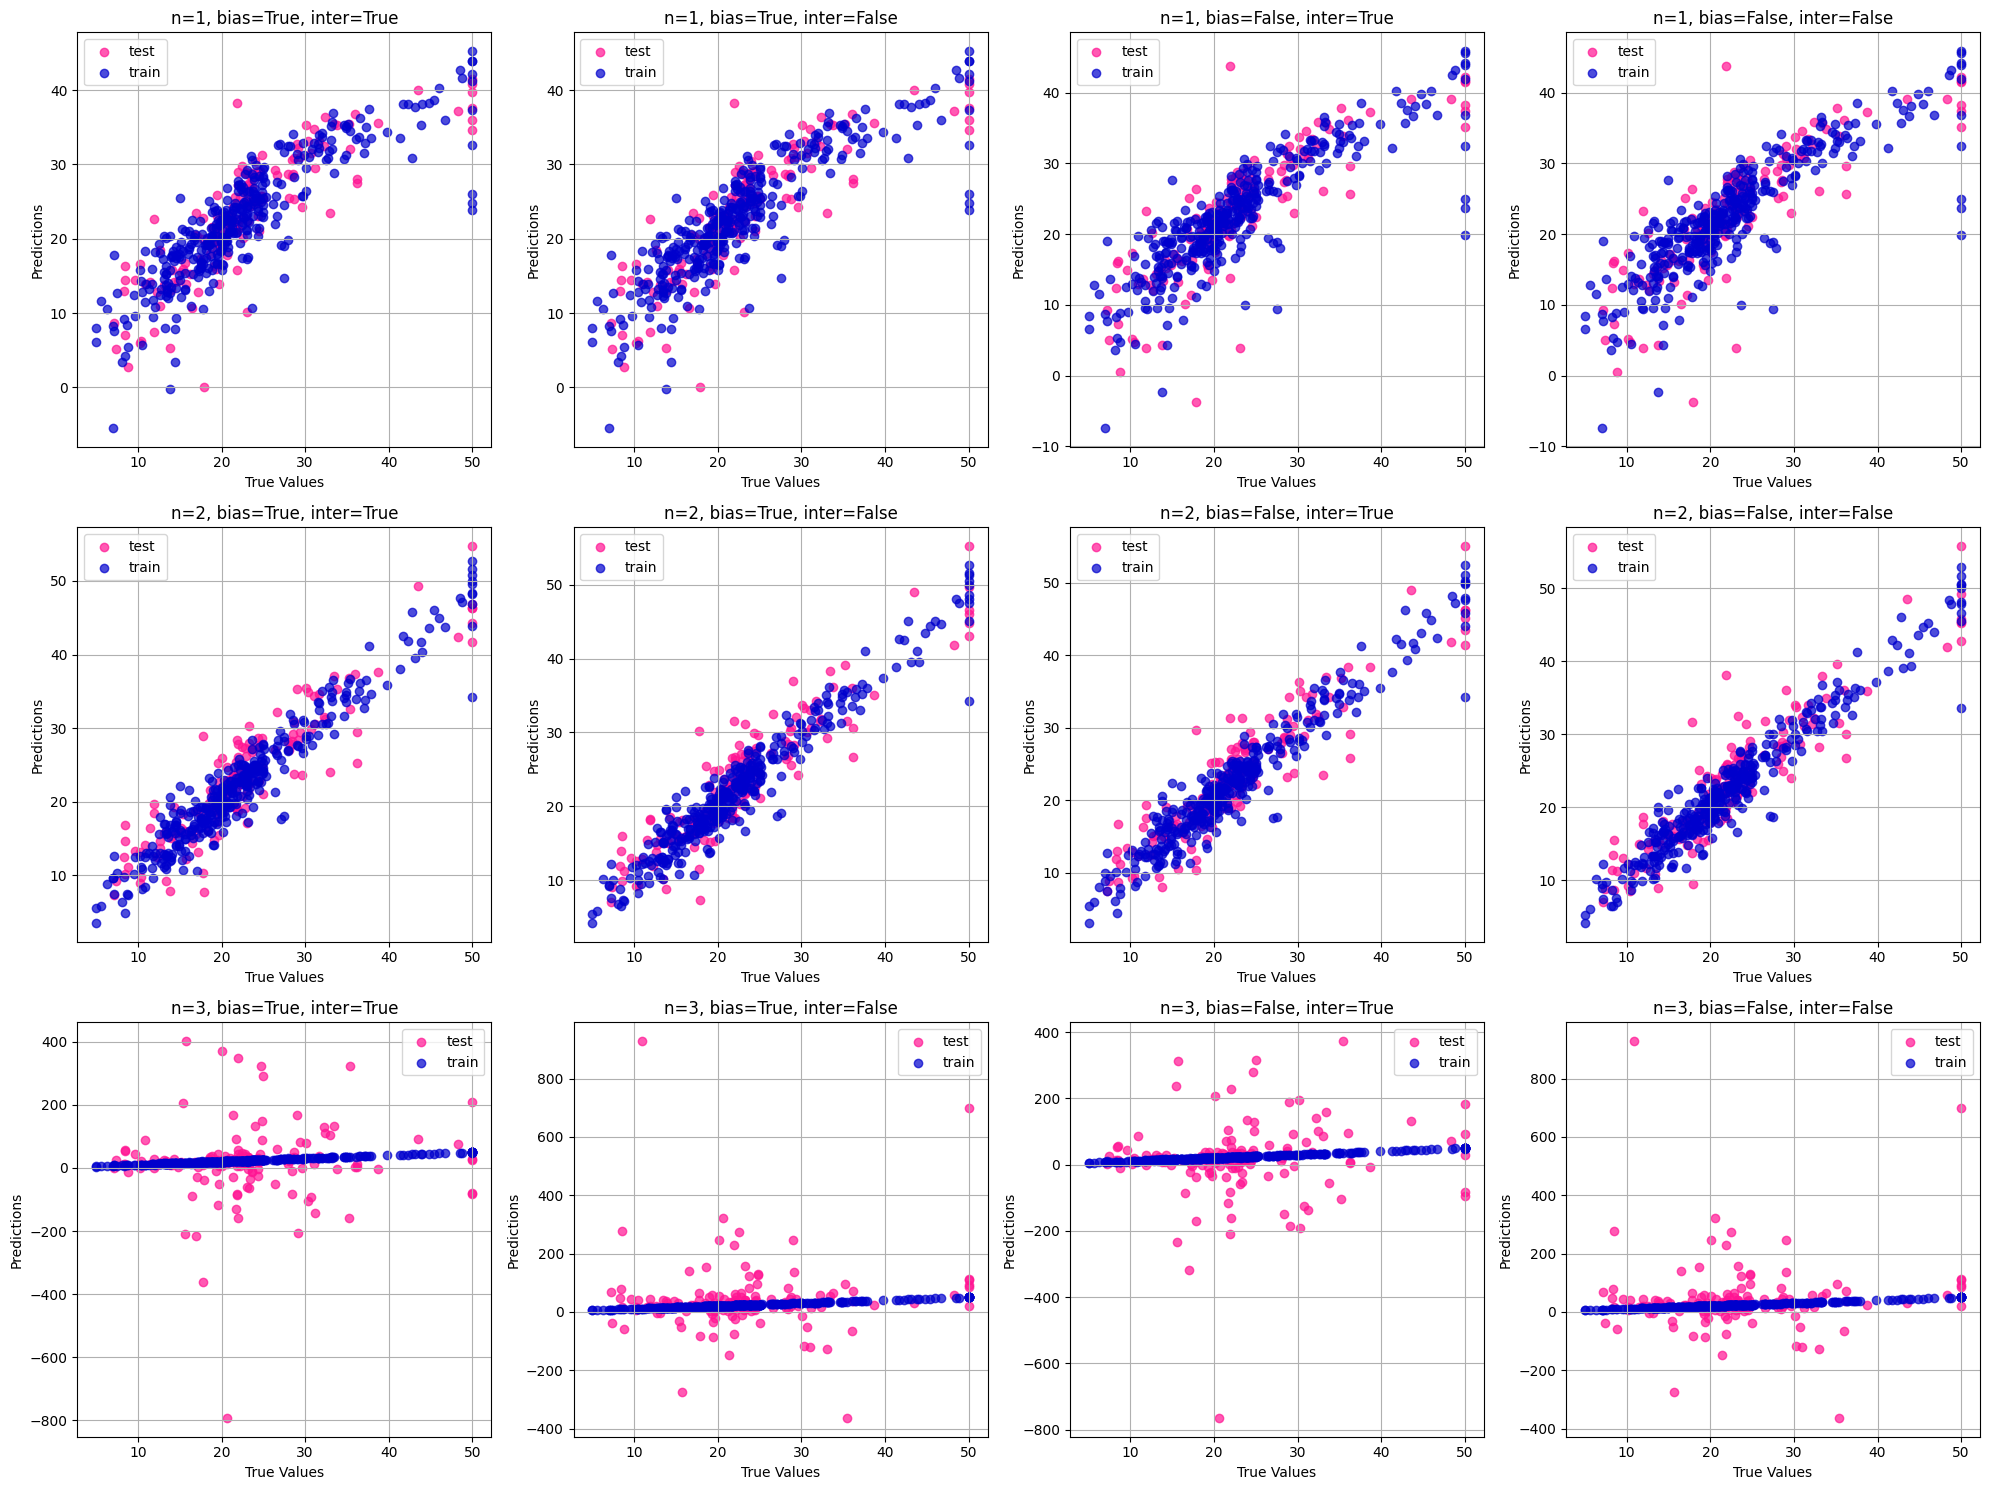

In [66]:
y = df['MEDV']
col = ["n", "include_bias", "interaction_only", "mae_ytest", "mean_ytest", "mae_ytrain", "mean_ytrain", "cond"]
res1 = []

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

i=0
for n in [1, 2, 3]:
  for include_bias in [True, False]:
    for interaction_only in [True, False]:
      X = df.values[:,:-1]
      poly = PolynomialFeatures(n, interaction_only=interaction_only, include_bias=include_bias)
      X = poly.fit_transform(X)

      Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.3,random_state=8)

      model = LinearRegression(fit_intercept=False)
      model = model.fit(Xtrain, ytrain)
      ypred = model.predict(Xtest)
      ypred0 = model.predict(Xtrain)
      condition_number = np.linalg.cond(X)
      res1.append([n, include_bias, interaction_only, mae(ytest, ypred), np.mean(ytest), mae(ytrain, ypred0), np.mean(ytrain), condition_number])

      ax = axes[i]
      ax.scatter(ytest, ypred, color='deeppink', label='test', alpha=0.7)
      ax.scatter(ytrain, ypred0, color='mediumblue', label='train', alpha=0.7)
      ax.set_title(f"n={n}, bias={include_bias}, inter={interaction_only}")
      ax.set_xlabel('True Values')
      ax.set_ylabel('Predictions')
      ax.grid()
      ax.legend()
      i+=1

res1 = pd.DataFrame(data=res1, columns=col)

plt.tight_layout()
plt.savefig("all_models_comparison.png")
plt.show()

In [67]:
res1.head(12)

,n,include_bias,interaction_only,mae_ytest,mean_ytest,mae_ytrain,mean_ytrain,cond
0,1,True,True,3.453293,22.815132,3.226875e+00,22.411582,1.511352e+04
1,1,True,False,3.453293,22.815132,3.226875e+00,22.411582,1.511352e+04
2,1,False,True,3.559376,22.815132,3.206187e+00,22.411582,8.497936e+03
3,1,False,False,3.559376,22.815132,3.206187e+00,22.411582,8.497936e+03
4,2,True,True,2.861379,22.815132,1.782080e+00,22.411582,1.182935e+08
5,2,True,False,2.763800,22.815132,1.682742e+00,22.411582,1.762943e+19
6,2,False,True,2.778896,22.815132,1.798231e+00,22.411582,6.643661e+07
7,2,False,False,2.699344,22.815132,1.686875e+00,22.411582,6.236801e+19
8,3,True,True,59.786092,22.815132,3.303864e-01,22.411582,7.840706e+22
9,3,True,False,54.614904,22.815132,8.495511e-09,22.411582,1.422419e+22


### Модели с n = 3 сильно переобучены, модели с n = 2 практически не переобучены, при этом показывают лучшую линейную зависимость, чем не переобученные модели с n = 1




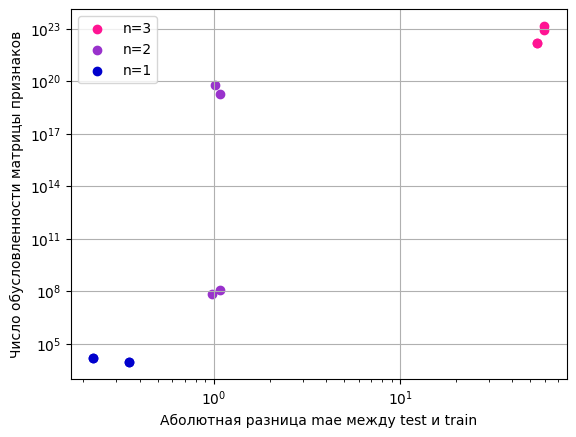

In [68]:
n1 = res1[res1['n'] == 1]
n2 = res1[res1['n'] == 2]
n3 = res1[res1['n'] == 3]
plt.scatter(abs(n3['mae_ytest'] - n3['mae_ytrain']), n3['cond'], color='deeppink', label='n=3')
plt.scatter(abs(n2['mae_ytest'] - n2['mae_ytrain']), n2['cond'], color='darkorchid', label='n=2')
plt.scatter(abs(n1['mae_ytest'] - n1['mae_ytrain']), n1['cond'], color='mediumblue', label='n=1')
plt.yscale('log')
plt.xscale('log')
plt.ylabel('Число обусловленности матрицы признаков')
plt.xlabel('Аболютная разница mae между test и train')
plt.grid()
plt.legend()
plt.show()

### По идее, высокая обусловленность (число) должна быть связана с тем, что решения имеют большую дисперсию => должна быть переобученность (чуть другие данные и сразу большое отклонение), в целом, на графике видна такая зависимость: значения с n = 3 переобучены и у них высокая обусловленность, значения с n = 2 переобучены слабо, у них плюс минус средняя обусловленность, у моделей с n = 1 вообще нет переобучения, и обусловленность маленькая.

# Задание 2

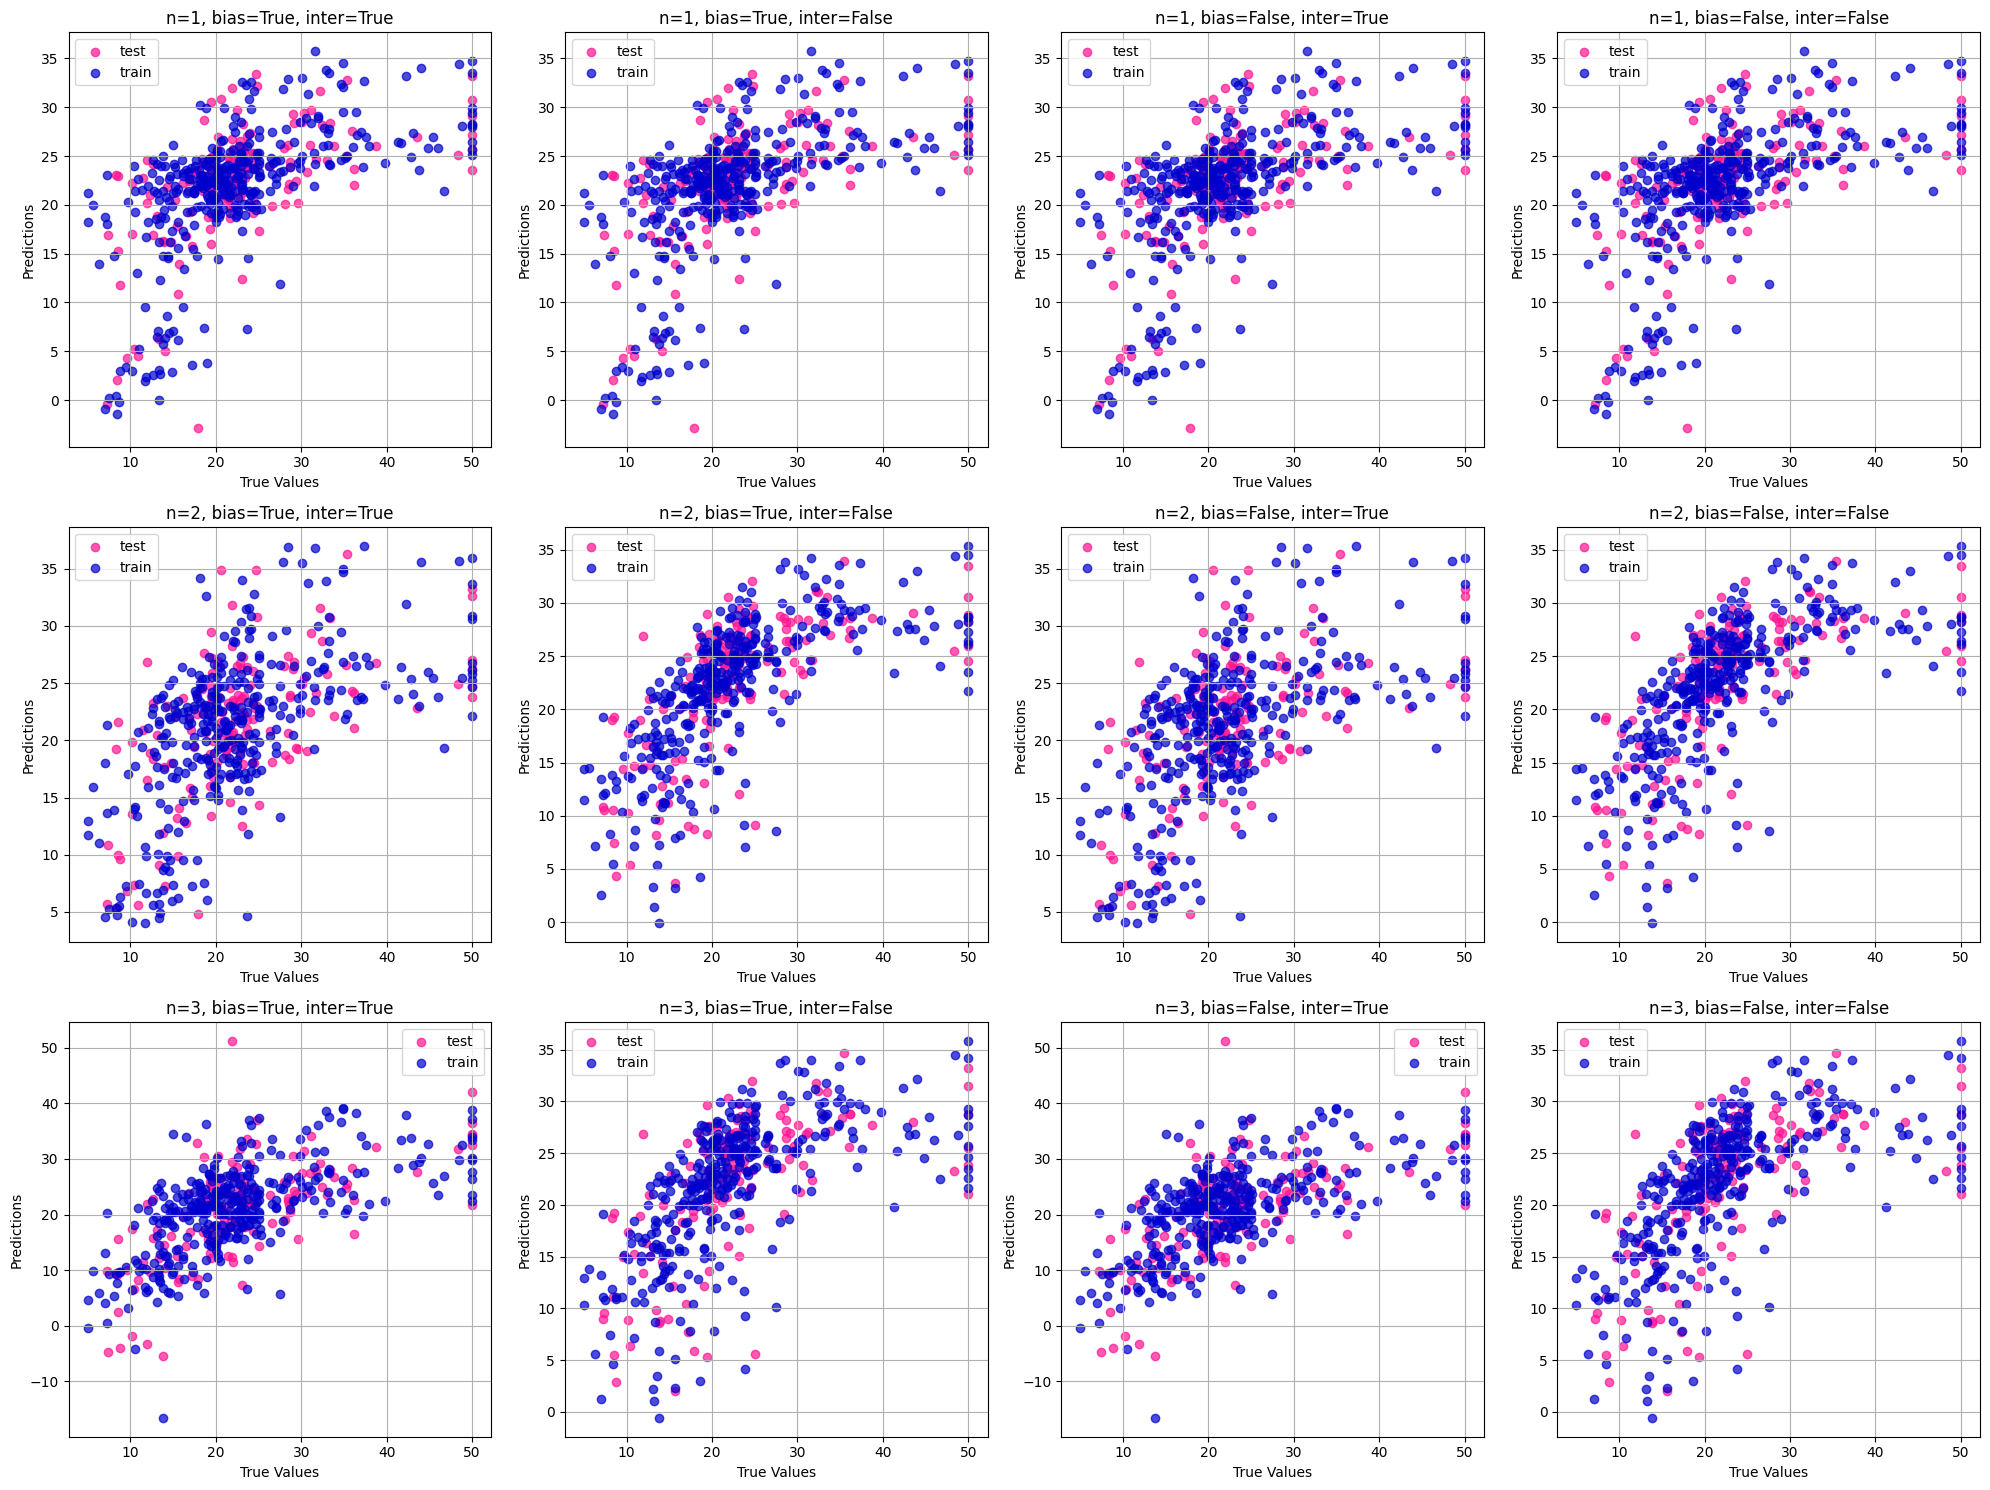

In [69]:
y = df['MEDV']
col = ["n", "include_bias", "interaction_only", "mae_ytest", "mean_ytest", "mae_ytrain", "mean_ytrain", "alpha", "cond"]
res2 = []

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

i=0
for n in [1, 2, 3]:
  for include_bias in [True, False]:
    for interaction_only in [True, False]:
      X = df.values[:,:-1]
      poly = PolynomialFeatures(n, interaction_only=interaction_only, include_bias=include_bias)
      X = poly.fit_transform(X)

      Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.3,random_state=8)

      model = LassoCV(cv=5, fit_intercept=False, max_iter=1000000)
      model = model.fit(Xtrain, ytrain)
      ypred = model.predict(Xtest)
      ypred0 = model.predict(Xtrain)
      condition_number = np.linalg.cond(X)
      res2.append([n, include_bias, interaction_only, mae(ytest, ypred), np.mean(ytest), mae(ytrain, ypred0), np.mean(ytrain), model.alpha_, condition_number])

      ax = axes[i]
      ax.scatter(ytest, ypred, color='deeppink', label='test', alpha=0.7)
      ax.scatter(ytrain, ypred0, color='mediumblue', label='train', alpha=0.7)
      ax.set_title(f"n={n}, bias={include_bias}, inter={interaction_only}")
      ax.set_xlabel('True Values')
      ax.set_ylabel('Predictions')
      ax.grid()
      ax.legend()
      i+=1

res2 = pd.DataFrame(data=res2, columns=col)

plt.tight_layout()
plt.savefig("all_models_comparison.png")
plt.show()

In [70]:
res2.head(12)

,n,include_bias,interaction_only,mae_ytest,mean_ytest,mae_ytrain,mean_ytrain,alpha,cond
0,1,True,True,5.561690,22.815132,5.750302,22.411582,8.526503e+00,1.511352e+04
1,1,True,False,5.561690,22.815132,5.750302,22.411582,8.526503e+00,1.511352e+04
2,1,False,True,5.561689,22.815132,5.750298,22.411582,8.526503e+00,8.497936e+03
3,1,False,False,5.561689,22.815132,5.750298,22.411582,8.526503e+00,8.497936e+03
4,2,True,True,5.664871,22.815132,5.955030,22.411582,3.022888e+03,1.182935e+08
5,2,True,False,5.035029,22.815132,4.988557,22.411582,3.791943e+03,1.762943e+19
6,2,False,True,5.664871,22.815132,5.955030,22.411582,3.022888e+03,6.643661e+07
7,2,False,False,5.035029,22.815132,4.988557,22.411582,3.791943e+03,6.236801e+19
8,3,True,True,5.970997,22.815132,5.881774,22.411582,2.060400e+05,7.840706e+22
9,3,True,False,5.422724,22.815132,5.305391,22.411582,1.943975e+06,1.422419e+22


### Теперь модель не переобучается нигде, но показатели mae ухудшились, на графиках тенденция стала еле различимой. Можно сделать вывод, что модель ухудшилась

/tmp/ipython-input-295050808.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


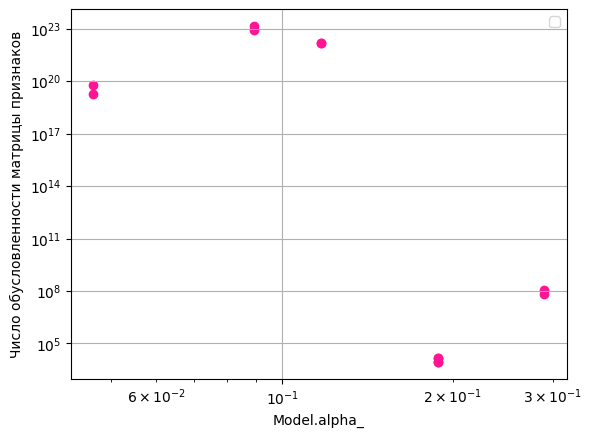

In [75]:
plt.scatter(abs(res2['mae_ytest'] - res2['mae_ytrain']), res2['cond'], color='deeppink')
plt.yscale('log')
plt.xscale('log')
plt.ylabel('Число обусловленности матрицы признаков')
plt.xlabel('Model.alpha_')
plt.grid()
plt.legend()
plt.show()

### Похоже на то, что с увеличением Model.alpha_ уменьшается число обусловленности, но это выражено очень неявно. Ну и данных мало 😖

# Задание 3

In [72]:
concated = pd.concat([res1, res2])
mask = (concated['mae_ytest'] == concated['mae_ytest'].min())
tries = concated[mask]
tries

,n,include_bias,interaction_only,mae_ytest,mean_ytest,mae_ytrain,mean_ytrain,cond,alpha
7,2,False,False,2.699344,22.815132,1.686875,22.411582,6.236801e+19,NaN


ytest --  5.035265658694127 22.815131578947366
ytrain --  4.988995105913401 22.411581920903956
condition_number --  6.236800699065273e+19


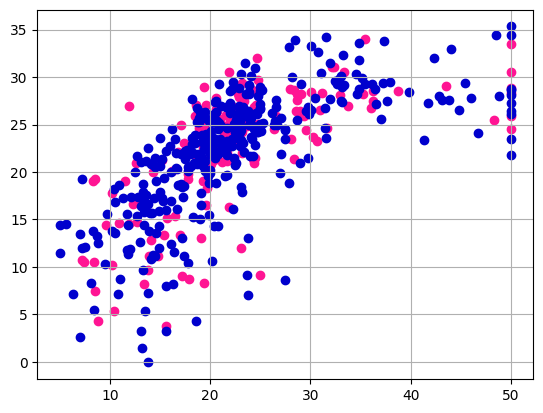

In [73]:
y = df['MEDV']
X = df.values[:,:-1]
poly = PolynomialFeatures(2, interaction_only=False, include_bias=False)
X = poly.fit_transform(X)

Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.3,random_state=8)

model = ElasticNetCV(fit_intercept=False)
model = model.fit(Xtrain, ytrain)
ypred = model.predict(Xtest)
ypred0 = model.predict(Xtrain)
condition_number = np.linalg.cond(X)

print(f"ytest -- ", mae(ytest, ypred), np.mean(ytest))
print(f"ytrain -- ",  mae(ytrain, ypred0), np.mean(ytrain))
print(f"condition_number -- ", condition_number)

plt.scatter(ytest, ypred, color='deeppink')
plt.scatter(ytrain, ypred0, color='mediumblue')
plt.grid()
plt.show()

### Результат ухудшился, это видно не только по mae, но и по графику, где зависимость стала менее явной, при этом уменьшилось переобучение (которое было заметно в легкой степени)